In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Digital_Payment_Fraud_Detection_Dataset.csv")


In [3]:
#General checking
df.head()
df.shape
df.columns
df.dtypes
df.isnull().sum()
df.duplicated().sum()
df["fraud_label"].value_counts()
df["fraud_label"].value_counts(normalize=True) * 100
df["transaction_amount"].describe()
df.describe()

,transaction_amount,account_age_days,transaction_hour,previous_failed_attempts,avg_transaction_amount,is_international,ip_risk_score,login_attempts_last_24h,fraud_label
count,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000
mean,24813.534161,1006.904533,11.435867,2.013600,15129.061027,0.100667,0.505026,4.995067,0.065200
std,14434.742371,575.632925,6.950899,1.421578,8597.760720,0.300907,0.289647,2.593879,0.246895
min,50.580000,10.000000,0.000000,0.000000,102.790000,0.000000,0.000000,1.000000,0.000000
25%,12272.785000,502.750000,5.000000,1.000000,7725.842500,0.000000,0.257000,3.000000,0.000000
50%,24715.550000,1018.000000,11.000000,2.000000,15074.810000,0.000000,0.502000,5.000000,0.000000
75%,37288.375000,1505.000000,18.000000,3.000000,22573.062500,0.000000,0.759000,7.000000,0.000000
max,49985.900000,1999.000000,23.000000,4.000000,29994.290000,1.000000,1.000000,9.000000,1.000000


In [4]:
# Fraud distrubution
fraud_summary = (
    df["fraud_label"]
    .value_counts()
    .rename(index={0: "Legitimate", 1: "fraud"})
    .reset_index()
)
fraud_summary.columns = ["transaction_status", "transaction_count"]
fraud_summary["percentage"] = (
    fraud_summary["transaction_count"]
    / fraud_summary["transaction_count"].sum() * 100
)
fraud_summary


,transaction_status,transaction_count,percentage
0,Legitimate,7011,93.48
1,fraud,489,6.52


In [7]:
# Fraud amount analysis
amount_by_fraud = (
    df.groupby("fraud_label")["transaction_amount"]
    .agg(["count","mean", "median", "min", "max"])
    .reset_index()
)
amount_by_fraud["fraud_label"] = amount_by_fraud["fraud_label"].map({
    0: "legitimate", 
    1: "Fraud"
})
amount_by_fraud

,fraud_label,count,mean,median,min,max
0,legitimate,7011,24852.406089,24755.12,50.58,49973.06
1,Fraud,489,24256.210879,24260.58,245.72,49985.90


In [8]:
# Fraud by payment mode
payment_mode =(
    df.groupby("payment_mode")
    .agg(
        total_transactions = ("transaction_id", "count"),
        fraud_transactions = ("fraud_label", "sum"),
        total_amount = ("transaction_amount", "sum"),
        fraud_amount = ("transaction_amount", lambda x: x[df.loc[x.index, "fraud_label"] == 1].sum())
    )
    .reset_index()
)
payment_mode["fraud_rate"] = (
    payment_mode["fraud_transactions"] 
    / payment_mode["total_transactions"] * 100
)
payment_mode = payment_mode.sort_values(
    "fraud_rate",
    ascending=False)
payment_mode

,payment_mode,total_transactions,fraud_transactions,total_amount,fraud_amount,fraud_rate
0,Card,1912,135,47261372.44,3435491.31,7.060669
1,NetBanking,1862,120,46050122.79,2736001.31,6.444683
2,UPI,1874,120,46288043.80,2774427.24,6.403415
3,Wallet,1852,114,46501967.18,2915367.26,6.155508


In [9]:
#Fraud by transaction type
transaction_type_risk = (
    df.groupby("transaction_type")
    .agg(
        total_transactions = ("transaction_id", "count"),
        fraud_transactions = ("fraud_label", "sum"),
        total_amount = ("transaction_amount", "sum")
    )
    .reset_index()
)
transaction_type_risk["fraud_rate"] = (
    transaction_type_risk["fraud_transactions"]
    / transaction_type_risk["total_transactions"] * 100
)
transaction_type_risk.sort_values(
    "fraud_rate",
    ascending=False)
transaction_type_risk

,transaction_type,total_transactions,fraud_transactions,total_amount,fraud_rate
0,Payment,2511,159,61907185.13,6.332139
1,Transfer,2490,160,61698443.59,6.425703
2,Withdrawal,2499,170,62495877.49,6.802721


In [10]:
# Fraud by device
device_type = (
    df.groupby("device_type")
    .agg(
        total_transactions = ("transaction_id", "count"),
        fraud_transactions = ("fraud_label", "sum")
    )
    .reset_index()
)
device_type["fraud_rate"] = (
    device_type["fraud_transactions"] 
    / device_type["total_transactions"] * 100
)
device_type.sort_values(
    "fraud_rate",
    ascending=False)
device_type

,device_type,total_transactions,fraud_transactions,fraud_rate
0,Android,2478,172,6.941082
1,Web,2537,152,5.991328
2,iOS,2485,165,6.639839


In [11]:
# Risk by location 
international_risk = (
    df.groupby("is_international")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_label", "sum"),
        total_amount=("transaction_amount", "sum")
    )
    .reset_index()
)
international_risk["fraud_rate"] = (
    international_risk["fraud_transactions"] 
    / international_risk["total_transactions"] *100
)
international_risk

,is_international,total_transactions,fraud_transactions,total_amount,fraud_rate
0,0,6745,448,1.673191e+08,6.641957
1,1,755,41,1.878245e+07,5.430464


In [12]:
# Fraud Transaction by hour
hourly_risk = (
    df.groupby("transaction_hour") 
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("fraud_label", "sum")
    )
    .reset_index()
)
hourly_risk["fraud_rate"] =(
    hourly_risk["fraud_transactions"]
    / hourly_risk["total_transactions"] *100
)
hourly_risk.sort_values("fraud_rate", ascending=False)


,transaction_hour,total_transactions,fraud_transactions,fraud_rate
19,19,313,29,9.265176
14,14,296,27,9.121622
6,6,330,27,8.181818
4,4,286,23,8.041958
9,9,341,26,7.624633
15,15,297,22,7.407407
12,12,312,23,7.371795
22,22,333,23,6.906907
0,0,306,21,6.862745
3,3,357,24,6.722689


In [13]:
# IP risk score
ip_risk = (
    df.groupby("fraud_label")["ip_risk_score"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)
ip_risk["fraud_label"] = ip_risk["fraud_label"].map({ 
    0: "Legitimate",
    1: "Fraud"
})
ip_risk

,fraud_label,count,mean,median,min,max
0,Legitimate,7011,0.504771,0.503,0.0,1.000
1,Fraud,489,0.508689,0.485,0.0,0.995


In [14]:
#Failed transactions attempts / fraud
attempts_risk = (
    df.groupby("fraud_label")["previous_failed_attempts"]
    .agg(["mean", "median", "max"])
    .reset_index ()
)
attempts_risk["fraud_label"] = attempts_risk["fraud_label"].map({
    0: "Legitimate",
    1: "Fraud" 
})
attempts_risk

,fraud_label,mean,median,max
0,Legitimate,2.007845,2.0,4
1,Fraud,2.096115,2.0,4


In [15]:
#Failed login attempts / fraud
login_risk = (
    df.groupby("fraud_label")["login_attempts_last_24h"]
    .agg(["mean", "median", "max"])
    .reset_index ()
)
login_risk["fraud_label"] = login_risk["fraud_label"].map({
    0: "Legitimate", 
    1: "Fraud" 
})
login_risk


,fraud_label,mean,median,max
0,Legitimate,4.983882,5.0,9
1,Fraud,5.155419,5.0,9


In [16]:
# Account age risk / fraud 
account_age_risk = (
    df.groupby("fraud_label")["account_age_days"]
    .agg(["mean", "median", "min", "max"])
    .reset_index()
)

account_age_risk["fraud_label"] = account_age_risk["fraud_label"].map({
    0: "Legitimate",
    1: "Fraud"
})

account_age_risk

,fraud_label,mean,median,min,max
0,Legitimate,1002.402225,1012.0,10,1999
1,Fraud,1071.456033,1108.0,10,1996


In [18]:
df["amount_category"] = pd.cut(
    df["transaction_amount"],
    bins=[-float("inf"), 1000, 3000, 7000, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)

In [19]:
df["account_age_category"] = pd.cut(
    df["account_age_days"],
    bins=[-1, 30, 90, 365, float("inf")],
    labels=["New", "Young", "Established", "Mature"]
)

In [ ]:
df["failed_attempt_category"] = pd.cut(
    df["previous_failed_attempts"],
    bins=[-1,0,1,4, float("inf")],
    labels=["None", "Low", "Medium", "High"]
)

In [ ]:
df['ip_risk_category'] = pd.cut(
    df['ip_risk_score'],
    bins=[0, 0.3, 0.6, 0.8, 1.0],
    labels=['Low', 'Medium', 'High', 'Critical'],
    include_lowest=True
)

In [ ]:
df["login_attempt_category"] = pd.cut (
    df["login_attempts_last_24h"],
    bins=[-1,2,5,10, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)

In [ ]:
df['risk_level'] = pd.qcut(
    df['ip_risk_score'],
    q=[0, 0.5, 0.8, 0.95, 1.0],
    labels=['Low', 'Medium', 'High', 'Critical']
)

In [20]:
print(df.columns.tolist())

['transaction_id', 'user_id', 'transaction_amount', 'transaction_type', 'payment_mode', 'device_type', 'device_location', 'account_age_days', 'transaction_hour', 'previous_failed_attempts', 'avg_transaction_amount', 'is_international', 'ip_risk_score', 'login_attempts_last_24h', 'fraud_label', 'amount_category', 'account_age_category']


In [27]:
# View selected columns
df[
   ['transaction_id', 'user_id', 'transaction_amount', 'transaction_type', 'payment_mode', 'device_type', 'device_location', 'account_age_days', 'transaction_hour', 'previous_failed_attempts', 'avg_transaction_amount', 'is_international', 'ip_risk_score', 'login_attempts_last_24h', 'fraud_label', 'amount_category', 'account_age_category']

].head(20)

,transaction_id,user_id,transaction_amount,transaction_type,payment_mode,device_type,device_location,account_age_days,transaction_hour,previous_failed_attempts,avg_transaction_amount,is_international,ip_risk_score,login_attempts_last_24h,fraud_label,amount_category,account_age_category
0,T1,U3756,18758.28,Transfer,UPI,Web,Hyderabad,895,14,1,25535.84,0,0.718,4,0,Very High,Mature
1,T2,U7899,47538.18,Payment,Wallet,iOS,Hyderabad,918,21,0,3955.85,0,0.525,9,0,Very High,Mature
2,T3,U1765,36613.10,Payment,Card,Android,Chennai,1506,8,4,22727.71,0,0.985,9,0,Very High,Mature
3,T4,U8850,29952.99,Payment,Wallet,iOS,Chennai,800,1,3,18095.89,0,0.797,2,0,Very High,Mature
4,T5,U9049,7843.13,Payment,UPI,Web,Delhi,301,4,1,9317.49,1,0.468,1,0,Very High,Established
5,T6,U1787,7841.93,Transfer,NetBanking,Web,Hyderabad,1992,20,3,4177.23,0,0.583,3,0,Very High,Mature
6,T7,U8763,2951.28,Transfer,UPI,Android,Hyderabad,1285,22,4,11451.45,0,0.045,8,1,Medium,Mature
7,T8,U1439,43315.50,Transfer,UPI,Web,Hyderabad,1621,4,4,13297.18,0,0.965,4,0,Very High,Mature
8,T9,U6660,30075.69,Transfer,UPI,Android,Mumbai,184,11,0,4308.80,0,0.363,5,0,Very High,Established
9,T10,U3566,35418.23,Payment,Card,iOS,Hyderabad,118,9,3,20136.79,0,0.662,5,0,Very High,Established


In [ ]:
df.isnull().sum()
df.to_csv(
    "Digital_Payment_Fraud_Analytics_Cleaned.csv",
    index=False
)

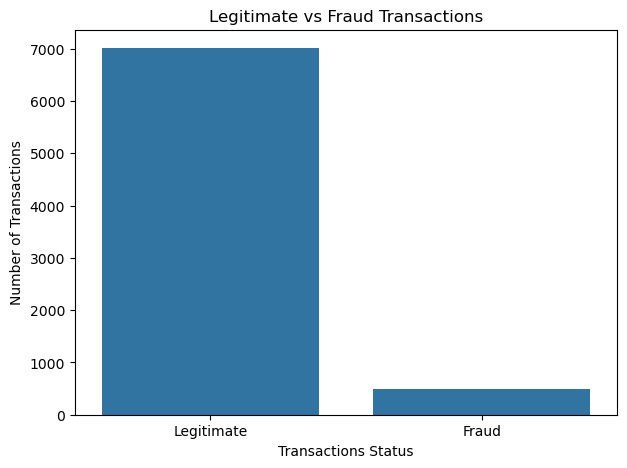

In [30]:
fraud_counts = df["fraud_label"].map({
    0: "Legitimate",
    1: "Fraud"
}).value_counts()

plt.figure(figsize=(8,5))
sns.barplot(x=fraud_counts.index, y=fraud_counts.values)

plt.title("Legitimate vs Fraud Transactions")
plt.xlabel("Transactions Status")
plt.ylabel("Number of Transactions")
plt.show()

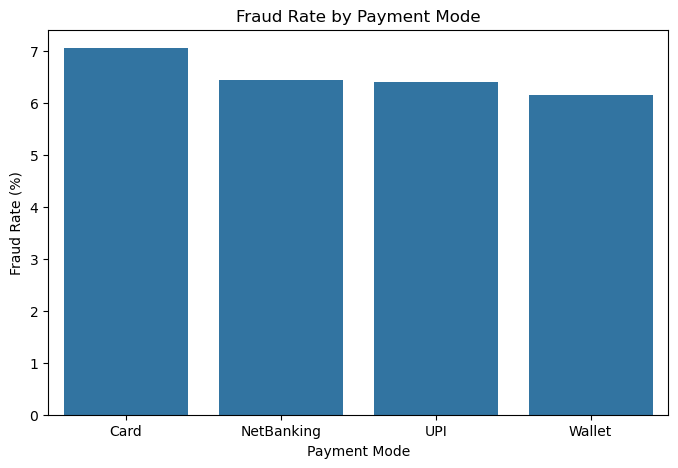

In [35]:
plt.figure(figsize=(8,5))
sns.barplot(data=payment_mode, x="payment_mode", y="fraud_rate")

plt.title("Fraud Rate by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Fraud Rate (%)")
plt.show()

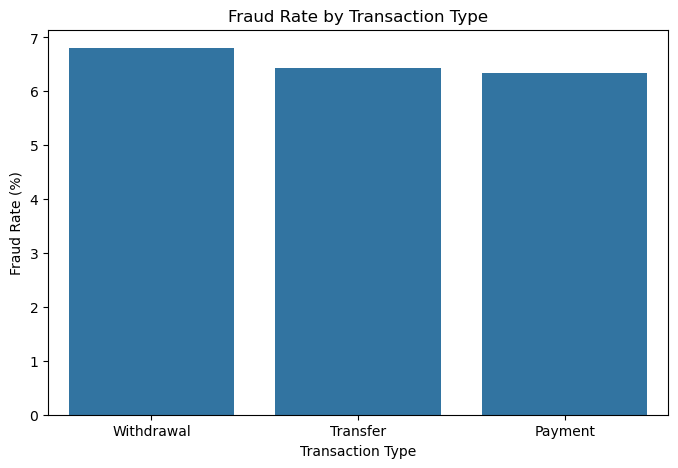

In [38]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=transaction_type_risk.sort_values("fraud_rate", ascending=False),
    x="transaction_type",
    y="fraud_rate"
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.show()